In [27]:
import matplotlib.pyplot as plt
import math
import random
import matplotlib.animation as animation
import time
from IPython.display import clear_output, display

class Point:
    def __init__(self, x, y, dx=0, dy=0, mass=3):
        self.mass = mass

        self.x = x
        self.y = y

        self.dx = dx
        self.dy = dy

    def move_point(self, dt):
        self.x += self.dx * dt
        self.y += self.dy * dt

def dist_between(point1: Point, point2: Point):
    dist_x = point2.x - point1.x
    dist_y = point2.y - point1.y
    diag = math.sqrt(dist_x**2 + dist_y**2)

    return dist_x, dist_y, diag

In [28]:
def generate_point_data():
    return random.uniform(1,3), random.uniform(-1,1), random.uniform(-1,1), random.uniform(-1,1)/10, random.uniform(-1,1)/10

In [29]:
# n = 2
# points = [Point(*generate_point_data()) 
#           for i in range(n)]
points = [Point(-1, 1, 0, -1),
          Point(1, 1, -1, 0), 
          Point(0, -1, 1, 0), 
          ]

# for point in points:
#     print(point.x, point.y, point.dx, point.dy)

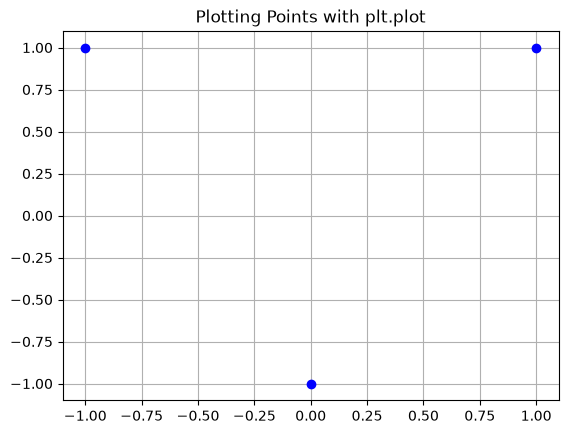

In [30]:
def plt_points(points: dict, pick_color: str):
    x = [point.x for point in points]
    y = [point.y for point in points]

    # The 'o' string shorthand means "dots only, no connecting lines"
    plt.plot(x, y, 'o', color=pick_color) 

    plt.title("Plotting Points with plt.plot")
    plt.grid(True)
    plt.show()
    return plt

plot = plt_points(points, "blue")

In [31]:
def update_velocity(points, gravity=1, dt=1, soft=0.5):
    for point in points:
        ddx, ddy = 0, 0
        for other_point in points:
            dist_x, dist_y, full_dist = dist_between(point, other_point)
            r_dist = (full_dist**2 + soft**2) ** 1.5
            
            ratio = gravity * other_point.mass / r_dist

            ddx += dist_x * ratio
            ddy += dist_y * ratio

        point.dx += ddx * dt
        point.dy += ddy * dt

def update_position(points, dt):
    for point in points:
        point.move_point(dt)

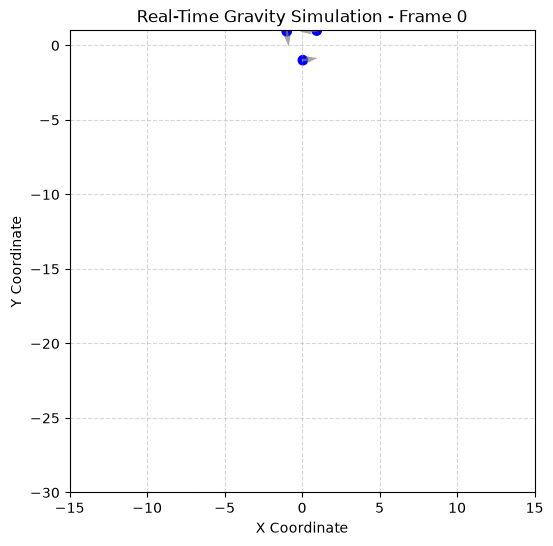

In [32]:
plt.ion() 

fig, ax = plt.subplots(figsize=(6, 6))
# Pre-calculate masses if they don't change over time
masses = [15 * point.mass for point in points] 
n = 15    
my_dt = 0.05

ax.set_xlim(-n, n)
ax.set_ylim(-2*n, 1)
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")

# Initialize artists
x_init = [p.x for p in points]
y_init = [p.y for p in points]
dx_init = [p.dx for p in points]
dy_init = [p.dy for p in points]

scat = ax.scatter(x_init, y_init, s=masses, color="blue")
quiv = ax.quiver(x_init, y_init, dx_init, dy_init, 
                 angles='xy', scale_units='xy', scale=1, 
                 color='gray', alpha=0.7, width=0.005)
title = ax.set_title("Real-Time Gravity Simulation")

# --- Live Continuous Loop ---
try:
    frame = 0
    while plt.fignum_exists(fig.number): # Runs until you close the plot window
        # 1. Physics Calculations
        update_velocity(points=points, gravity=3, dt=my_dt)
        
        x_old = [point.x for point in points]
        y_old = [point.y for point in points]
        dx = [point.dx for point in points]
        dy = [point.dy for point in points]
        
        update_position(points, my_dt)
        
        x_new = [point.x for point in points]
        y_new = [point.y for point in points]
        
        # 2. Update the visual artists dynamically
        scat.set_offsets(list(zip(x_new, y_new)))
        quiv.set_offsets(list(zip(x_old, y_old)))
        quiv.set_UVC(dx, dy)
        title.set_text(f"Real-Time Gravity Simulation - Frame {frame}")
        
        # 3. Redraw the canvas and flush GUI events instantly
        fig.canvas.draw()
        fig.canvas.flush_events()
        
        # 4. Control frame rate (e.g., 0.01s pause ~ 60 FPS target)
        plt.pause(0.001)
        
        frame += 1

except KeyboardInterrupt:
    # Safely exit if interrupted
    pass
finally:
    plt.ioff() # Turn interactive mode off when finished

In [33]:

# Pre-calculate masses if they don't change over time
masses = [15 * point.mass for point in points] 
n = 15    
my_dt = 0.05

# --- The Simulation Loop ---
for frame in range(1000):  # Change 50 to however many steps you want to simulate

    # 1. Physics Calculations for this step
    update_velocity(points=points, gravity=3, dt=my_dt)
    
    # Capture state BEFORE position update
    x_old = [point.x for point in points]
    y_old = [point.y for point in points]
    dx = [point.dx for point in points]
    dy = [point.dy for point in points]
    
    # Perform position update
    update_position(points, my_dt)
    
    # Capture state AFTER position update
    x_new = [point.x for point in points]
    y_new = [point.y for point in points]
    
    # 2. Clear the previous frame
    clear_output(wait=True)
    
    # 3. Create a fresh plot for this frame
    fig, ax = plt.subplots(figsize=(6, 6))
        
    # Draw velocity/movement arrows
    ax.quiver(
        x_old, y_old, dx, dy, 
        angles='xy', scale_units='xy', scale=1, 
        color='gray', alpha=0.7, width=0.005
    )
    
    # Plot current position (Red)
    ax.scatter(x_new, y_new, s=masses, color="blue") 
    
    # Polishing & Constraints (Crucial to keep limits identical every frame)
    ax.set_xlim(-n, n)
    ax.set_ylim(-2*n, 1)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_title(f"Tracking Point Movements - Step {frame}")
    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    
    # 4. Show the frame and clean up memory
    display(fig)
    plt.close(fig) 
    
    # 5. Pause slightly so your eyes can trace the movement
    #time.sleep(0.0001) 

KeyboardInterrupt: 